# R-KalWeNN no House Prices — experimentos do LAFusion

Notebook do artigo. Três experimentos, na ordem em que entram no texto.

**1. Erro por agregação.** ReW contra R-KalWeNN com thermometer e tupla fixos em
27 e 6, uma linha por função de agregação, com MAE, RMSE e R². Os
hiperparâmetros do filtro ficam num valor padrão, declarado e justificado na
seção 1.

**2. Thermometer e tupla.** Como o erro varia com os dois, quantas visitas cada
endereço recebe em cada configuração, e a escolha do ponto de operação a partir
dessas duas coisas.

**3. Hiperparâmetros do filtro.** Com o ponto de operação escolhido, o efeito de
`q`, `r` e `p0` em cada campo, um gráfico por parâmetro.

A infraestrutura das seções 0 a 4 é a mesma do notebook 06. O que muda é o que
vem da seção 5 em diante.

---
## 0. Configuração, dados e modelos

Células iguais às do notebook 06.

In [23]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_KAL, COR_REW, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py

# ── codificação, fixada na configuração vencedora da varredura ───────────────
THERM        = 27            # bits de thermometer por atributo
ADDR         = 6             # bits por RAM node
SEED_MAPPING = 0

# ── referência publicada ─────────────────────────────────────────────────────
# Neurocomputing 416 (2020), Tabela 2: ReW no House Prices, média vencedora
# Median, MAE 0.278 com desvio 0. É o único baseline usado aqui.
REF_ARTIGO = 0.278

# ── estados iniciais, fixos nas duas variantes ───────────────────────────────
X0_C, X0_Y = 0.0, 0.0
SEEDS_GRID = (0, 1, 2)       # ordens de treino avaliadas por configuração

print(f"codificação: thermometer {THERM}, address {ADDR}, mapping seed {SEED_MAPPING}")
print(f"referência publicada (ReW, Median): MAE {REF_ARTIGO}")

codificação: thermometer 27, address 6, mapping seed 0
referência publicada (ReW, Median): MAE 0.278


In [24]:
class DynamicThermometer:
    """Termômetro por atributo, com faixa própria para cada um."""

    def __init__(self, sizes, minimos, maximos):
        self.sizes = list(sizes)
        self.limiares = []
        for n, mn, mx in zip(self.sizes, minimos, maximos):
            passo = (mx - mn) / n
            v, faixa = mn, []
            for _ in range(n):                # acumula, como o math::ranges
                faixa.append(v)
                v += passo
            self.limiares.append(np.asarray(faixa, dtype=float))
        self.size = int(np.sum(self.sizes))

    def transform(self, X):
        """(n_amostras, n_atributos) float -> (n_amostras, size) uint8."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        saida = np.empty((len(X), self.size), dtype=np.uint8)
        k = 0
        for i, faixa in enumerate(self.limiares):
            n = len(faixa)
            saida[:, k:k + n] = (X[:, [i]] > faixa[None, :]).astype(np.uint8)
            k += n
        return saida


print("DynamicThermometer definido")

DynamicThermometer definido


In [25]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [26]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaK:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaK"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class KSimpleMean(MediaK):
    nome = "K-SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class KPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class KHarmonicMean(MediaK):
    nome = "K-HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class KHarmonicPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class KExponentialMean(MediaK):
    nome = "K-ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class KMedian(MediaK):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "K-Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"K-SimpleMean": KSimpleMean(), "K-PowerMean(2)": KPowerMean(2),
            "K-HarmonicMean": KHarmonicMean(),
            "K-HarmonicPower(2)": KHarmonicPowerMean(2),
            "K-ExponentialMean": KExponentialMean(), "K-Median": KMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: K-SimpleMean, K-PowerMean(2), K-HarmonicMean, K-HarmonicPower(2), K-ExponentialMean, K-Median


In [27]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


In [28]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


In [29]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


In [30]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


In [31]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


In [32]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


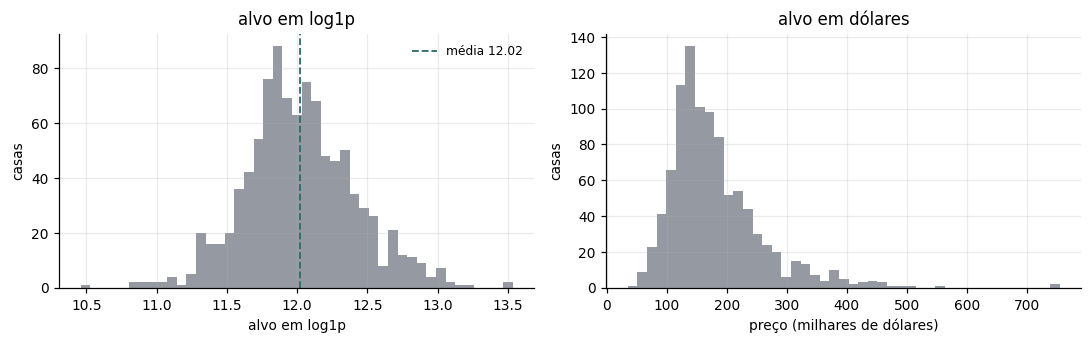

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [33]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_KAL, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=COR_REF, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_ARTIGO:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_ARTIGO:.3f} em log1p equivale a {np.expm1(REF_ARTIGO):.1%} de erro relativo")

In [34]:
mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
DT = DynamicThermometer([THERM] * N_ATRIB, mins, maxs)

Xb_train = DT.transform(X_train)
Xb_test  = DT.transform(X_test)

RETINA  = Xb_train.shape[1]
MAPPING = sorteia_mapping(RETINA, ADDR, seed=SEED_MAPPING)
RET_OBJ = Retina(ADDR, MAPPING)
N_RAMS  = RET_OBJ.n_rams
N_ADDR  = RET_OBJ.n_addr

ADDR_TR = RET_OBJ.enderecos(Xb_train)
ADDR_TE = RET_OBJ.enderecos(Xb_test)

visitas = np.zeros((N_RAMS, N_ADDR), dtype=int)
for i in range(N_TREINO):
    visitas[np.arange(N_RAMS), ADDR_TR[i]] += 1
ocupadas = visitas[visitas > 0]

print(f"retina   : {RETINA} bits  ({N_ATRIB} atributos x {THERM})")
print(f"address  : {ADDR} bits  ->  {N_RAMS} RAM nodes x {N_ADDR} endereços")
print(f"mapping  : {len(MAPPING)} bits, seed {SEED_MAPPING}")
print(f"\ncélulas ocupadas: {len(ocupadas):,} de {N_RAMS*N_ADDR:,}")
print(f"visitas por célula ocupada: mín {ocupadas.min()}, mediana "
      f"{int(np.median(ocupadas))}, máx {ocupadas.max()}")

retina   : 8964 bits  (332 atributos x 27)
address  : 6 bits  ->  1494 RAM nodes x 64 endereços
mapping  : 8964 bits, seed 0

células ocupadas: 23,172 de 95,616
visitas por célula ocupada: mín 1, mediana 6, máx 952


In [35]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        self.slots_fit = np.empty_like(addr_fit)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [ ]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    ATUALIZAÇÃO DE c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas,
                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    ATUALIZAÇÃO DE y   p_y cresce q_y uma vez por acesso, e a correção
                       roda só no acesso. Célula não acessada não é tocada
                       por nenhuma das duas.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else KSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        for i in ordem:
            s = idx.slots_fit[i]
            pp = PY[s] + self.q_y                      # predição, uma por visita
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


In [37]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "K-SimpleMean" in nomes:
        out["K-SimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "K-PowerMean(2)" in nomes:
        out["K-PowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-HarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["K-HarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "K-HarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["K-HarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "K-ExponentialMean" in nomes:
        out["K-ExponentialMean"] = fin(np.log((Cm * np.exp(Y)).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-Median" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["K-Median"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


IDX      = IndiceRK(RET_OBJ, ADDR_TR)
SLOTS_TE = IDX.slots(ADDR_TE)
print(f"IndiceRK do treino: {IDX.n_celulas:,} células ocupadas")
print("medias_vetorizadas definida")

IndiceRK do treino: 23,172 células ocupadas
medias_vetorizadas definida


In [38]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


def grid_kalman(indice, slots_te, y_tr, y_te, grids, seeds=SEEDS_GRID,
                nomes=None, mostrar=True, x0_c=X0_C, x0_y=X0_Y):
    """Grid conjunto das seis covariâncias, com a média variando junto.

    A média age só no predict, então cada configuração é treinada uma vez e
    todas as médias são lidas da mesma memória.
    """
    nomes = nomes or MEDIAS_NO_GRID
    combos = list(product(*grids))
    if mostrar:
        print(f"{len(combos)} covariâncias x {len(seeds)} seeds x {len(nomes)} médias")
    linhas, t0 = [], time.perf_counter()
    for n, (qc, rc, p0c, qy, ry, p0y) in enumerate(combos, 1):
        acum = {m: [] for m in nomes}
        for s in seeds:
            mod = RKalWeNN(indice.retina.address_size, indice.retina.mapping.ravel(),
                           q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                           x0_c=x0_c, x0_y=x0_y, seed=s, indice=indice).fit(y=y_tr)
            for nome, v in avalia(mod, slots_te, y_te, nomes).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            a = np.array([v[:3] for v in vs], dtype=float)
            linhas.append(dict(media=nome, q_c=qc, r_c=rc, p0_c=p0c,
                               q_y=qy, r_y=ry, p0_y=p0y,
                               MAE=a[:, 0].mean(), MAE_dp=a[:, 0].std(),
                               RMSE=a[:, 1].mean(), R2=a[:, 2].mean(),
                               nao_finito=int(max(v[3] for v in vs))))
        if mostrar and n % 50 == 0:
            el = time.perf_counter() - t0
            print(f"  {n:>3}/{len(combos)}   {el/60:.1f} min, "
                  f"faltam ~{el/n*(len(combos)-n)/60:.1f} min")
    g = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
    if mostrar:
        print(f"concluído em {(time.perf_counter()-t0)/60:.1f} min")
    return g


print("avalia e grid_kalman definidos")

avalia e grid_kalman definidos


---
## 1. Erro por agregação, com thermometer 27 e tupla 6

Comparação direta entre a Regression WiSARD e o R-KalWeNN na mesma codificação e
no mesmo mapeamento, uma linha por função de agregação.

Os seis hiperparâmetros do filtro ficam num **valor padrão**, medido no conjunto
de treino e não ajustado por busca, para que este experimento meça o efeito da
memória e não o efeito de um ajuste fino. São eles, com a leitura de cada um:

| | campo do peso | campo da estimativa |
|---|---|---|
| incerteza inicial | `p0_c = 1` | `p0_y = 1` |
| ruído de observação | `r_c` = mediana de visitas por endereço | `r_y` = variância dentro dos endereços dividida pela variância entre endereços |
| ruído de processo | `q_c` = 1 / mediana de visitas | `q_y` = `r_y` / mediana de visitas ao quadrado |

`r_c` é o número de visitas em que a confiança do endereço chega à metade, então
usar a mediana de visitas põe metade dos endereços de cada lado. `r_y` diz quanto
uma visita isolada vale contra o que o endereço já sabia: quanto menor, mais a
primeira observação é aceita de face. Os dois `q` fixam a janela de memória na
mediana de visitas, e nenhum deles é zero, porque sem ruído de processo a
recursão perde a dependência da ordem de apresentação.

Os estados iniciais são `x0_c = 0` e `x0_y` na média do alvo no treino.

A ReW é determinística dado o mapeamento. O R-KalWeNN depende da ordem de
apresentação, então ele roda em várias sementes e a tabela traz média e desvio.

In [39]:
# ── ponto de operação e hiperparâmetros padrão ──────────────────────────────
# Nome interno x nome exibido. O "(2)" das médias de potência é o expoente p = 2,
# que é o único usado aqui; o texto diz isso uma vez e as tabelas ficam limpas.
ROTULO_MEDIA = {"SimpleMean": "Simple", "PowerMean(2)": "Power",
                "HarmonicMean": "Harmonic", "HarmonicPower(2)": "Harmonic power",
                "ExponentialMean": "Exponential", "Median": "Median",
                "GeometricMean": "Geometric"}
rotulo = lambda n: ROTULO_MEDIA.get(n.replace("K-", ""), n.replace("K-", ""))

THERM_1, ADDR_1 = 27, 6
SEEDS_AGREG = (0, 1, 2, 3, 4)   # 5 ordens de apresentação

dt_1  = DynamicThermometer([THERM_1] * N_ATRIB, mins, maxs)
Xb_tr1, Xb_te1 = dt_1.transform(X_train), dt_1.transform(X_test)
map_1 = sorteia_mapping(Xb_tr1.shape[1], ADDR_1, seed=SEED_MAPPING)
ret_1 = Retina(ADDR_1, map_1)
atr_1, ate_1 = ret_1.enderecos(Xb_tr1), ret_1.enderecos(Xb_te1)
idx_1 = IndiceRK(ret_1, atr_1)
slots_te1 = idx_1.slots(ate_1)

# visitas por endereço e componentes de variância, no conjunto de treino
cont_1, soma_1, soma2_1 = [], [], []
for r_ in range(ret_1.n_rams):
    _, inv = np.unique(atr_1[:, r_], return_inverse=True)
    cont_1.append(np.bincount(inv))
    soma_1.append(np.bincount(inv, weights=y_train))
    soma2_1.append(np.bincount(inv, weights=y_train ** 2))
n_1 = np.concatenate(cont_1); s_1 = np.concatenate(soma_1); s2_1 = np.concatenate(soma2_1)
mu_1 = s_1 / n_1
mult = n_1 > 1
VAR_DENTRO = float((s2_1[mult] - n_1[mult] * mu_1[mult] ** 2).sum() / (n_1[mult] - 1).sum())
VAR_ENTRE = float(max(np.var(mu_1[mult], ddof=1)
                      - VAR_DENTRO * float(np.mean(1.0 / n_1[mult])), 1e-6))
MEDIANA_VIS = float(np.median(n_1))

PADRAO = dict(
    p0_c=1.0, r_c=MEDIANA_VIS,          q_c=MEDIANA_VIS / MEDIANA_VIS ** 2,
    p0_y=1.0, r_y=VAR_DENTRO / VAR_ENTRE,
)
PADRAO["q_y"] = PADRAO["r_y"] / MEDIANA_VIS ** 2
PADRAO["x0_c"], PADRAO["x0_y"] = 0.0, float(y_train.mean())

print(f"thermometer {THERM_1}, tupla {ADDR_1}  ->  {ret_1.n_rams} RAM nodes, "
      f"{idx_1.n_celulas:,} endereços ocupados")
print(f"visitas por endereço: mín {n_1.min()}, mediana {MEDIANA_VIS:.0f}, máx {n_1.max()}")
print(f"variância do alvo {y_train.var(ddof=1):.4f}  =  dentro {VAR_DENTRO:.4f}"
      f"  +  entre {VAR_ENTRE:.4f}   (intraclasse {VAR_ENTRE/(VAR_ENTRE+VAR_DENTRO):.3f})\n")
print("HIPERPARÂMETROS PADRÃO\n")
print(f"  campo do peso        p0_c = {PADRAO['p0_c']:<12.6g} "
      f"q_c = {PADRAO['q_c']:<12.6g} r_c = {PADRAO['r_c']:.6g}")
print(f"  campo da estimativa  p0_y = {PADRAO['p0_y']:<12.6g} "
      f"q_y = {PADRAO['q_y']:<12.6g} r_y = {PADRAO['r_y']:.6g}")
print(f"  estados iniciais     x0_c = {PADRAO['x0_c']:<12.6g} "
      f"x0_y = {PADRAO['x0_y']:.6g}")

thermometer 27, tupla 6  ->  1494 RAM nodes, 23,172 endereços ocupados
visitas por endereço: mín 1, mediana 6, máx 952
variância do alvo 0.1538  =  dentro 0.1237  +  entre 0.0876   (intraclasse 0.415)

HIPERPARÂMETROS PADRÃO

  campo do peso        p0_c = 1            q_c = 0.166667     r_c = 6
  campo da estimativa  p0_y = 1            q_y = 0.0392068    r_y = 1.41144
  estados iniciais     x0_c = 0            x0_y = 12.0215


In [40]:
# ── a tabela: ReW e R-KalWeNN, uma linha por média ──────────────────────────
# A cada execução a semente sorteia o mapeamento de bits para RAM nodes, que é a
# aleatoriedade que os dois modelos compartilham, e no R-KalWeNN ela também
# define a ordem de apresentação. Assim os dois têm desvio medido da mesma fonte.
NOMES_REW = list(medias_rew()); NOMES_KAL = list(medias_kal())

ss_tot = float(np.sum((y_test - y_test.mean()) ** 2))
acum = {("ReW", n): [] for n in NOMES_REW}
acum.update({("R-KalWeNN", n): [] for n in NOMES_KAL})
bits_1 = Xb_tr1.shape[1]

for sd in SEEDS_AGREG:
    mp = sorteia_mapping(bits_1, ADDR_1, seed=sd)
    ret = Retina(ADDR_1, mp)
    idx = IndiceRK(ret, ret.enderecos(Xb_tr1))
    slots = idx.slots(ret.enderecos(Xb_te1))

    # ReW: a memória não depende da média, então treina uma vez e troca a média
    rw = RegressionWiSARD(ADDR_1, medias_rew()[NOMES_REW[0]], mp).fit(Xb_tr1, y_train)
    for nome, m in medias_rew().items():
        rw.mean = m
        pr = np.asarray(rw.predict(Xb_te1), dtype=float)
        nf = int((~np.isfinite(pr)).sum())
        if nf:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        acum[("ReW", nome)].append((
            mean_absolute_error(y_test, pr),
            float(np.sqrt(mean_squared_error(y_test, pr))),
            1.0 - float(np.sum((y_test - pr) ** 2)) / ss_tot, nf))

    # R-KalWeNN: uma memória por execução, todas as médias saem do mesmo ajuste
    mod = RKalWeNN(ADDR_1, mp, indice=idx, seed=sd, **PADRAO).fit(y=y_train)
    for nome, v in avalia(mod, slots, y_test, NOMES_KAL).items():
        acum[("R-KalWeNN", nome)].append(v)

linhas = []
for (modelo, nome), vals in acum.items():
    v = np.array([[a, b, c] for a, b, c, _ in vals])
    linhas.append(dict(modelo=modelo, media=rotulo(nome),
                       MAE=v[:, 0].mean(), MAE_dp=v[:, 0].std(ddof=1),
                       RMSE=v[:, 1].mean(), R2=v[:, 2].mean(),
                       nao_finito=int(sum(nf for *_, nf in vals))))
tab1 = pd.DataFrame(linhas)
print(f"{len(SEEDS_AGREG)} execuções, mapeamento sorteado a cada uma\n")
print(tab1.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nReW publicada na tese (log1p): MAE {REF_ARTIGO:.3f}")
print(f"chutar a média do treino     : MAE {mae_media:.4f}")

amp = tab1.groupby("modelo").MAE.agg(lambda s: s.max() - s.min())
print("\namplitude de MAE entre as médias:")
for m, v in amp.items():
    print(f"  {m:10s} {v:.4f}")

5 execuções, mapeamento sorteado a cada uma

   modelo          media    MAE  MAE_dp   RMSE     R2  nao_finito
      ReW         Simple 0.2864  0.0002 0.3764 0.1415           0
      ReW          Power 0.2481  0.0001 0.3311 0.3360           0
      ReW       Harmonic 0.2481  0.0001 0.3313 0.3350           0
      ReW Harmonic power 0.2481  0.0001 0.3314 0.3348           0
      ReW    Exponential 0.2480  0.0001 0.3296 0.3418           0
      ReW         Median 0.2739  0.0006 0.3595 0.2171           0
R-KalWeNN         Simple 0.2565  0.0067 0.3400 0.2995           0
R-KalWeNN          Power 0.2566  0.0067 0.3400 0.2994           0
R-KalWeNN       Harmonic 0.2562  0.0066 0.3399 0.2996           0
R-KalWeNN Harmonic power 0.2561  0.0066 0.3399 0.2996           0
R-KalWeNN    Exponential 0.2575  0.0073 0.3398 0.3002           0
R-KalWeNN         Median 0.2776  0.0098 0.3635 0.1991           0

ReW publicada na tese (log1p): MAE 0.278
chutar a média do treino     : MAE 0.3151

amplitude de

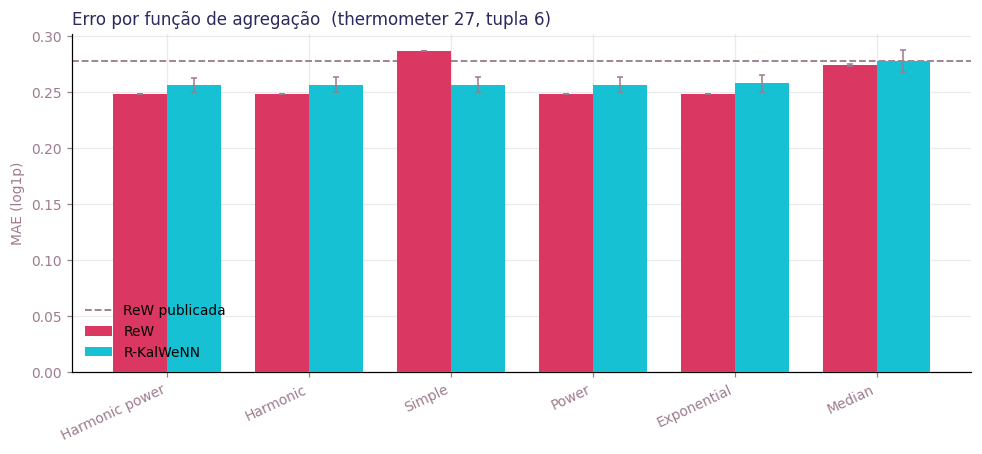

In [41]:
# ── figura: MAE por média, os dois modelos lado a lado ──────────────────────
C_REW, C_KAL, C_EIXO, C_TIT = "#db3763", "#16c1d4", "#9c7b8e", "#2b2a5e"

piv = tab1.pivot(index="media", columns="modelo", values="MAE").sort_values("R-KalWeNN")
dp = tab1.pivot(index="media", columns="modelo", values="MAE_dp").loc[piv.index]

x = np.arange(len(piv)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.2), facecolor="white")
ax.bar(x - w/2, piv["ReW"], w, yerr=dp["ReW"], color=C_REW, label="ReW",
       zorder=3, error_kw=dict(ecolor=C_EIXO, elinewidth=1, capsize=2))
ax.bar(x + w/2, piv["R-KalWeNN"], w, yerr=dp["R-KalWeNN"], color=C_KAL,
       label="R-KalWeNN", zorder=3,
       error_kw=dict(ecolor=C_EIXO, elinewidth=1, capsize=2))
ax.axhline(REF_ARTIGO, color=C_EIXO, ls="--", lw=1.2, label="ReW publicada")
ax.set_xticks(x); ax.set_xticklabels(piv.index, rotation=25, ha="right")
ax.set_ylabel("MAE (log1p)", color=C_EIXO)
ax.set_title(f"Erro por função de agregação  (thermometer {THERM_1}, tupla {ADDR_1})",
             color=C_TIT, fontsize=11, loc="left")
ax.tick_params(colors=C_EIXO)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

---
## 2. Estabilidade entre execuções

Mesmo ponto de operação da Seção 1, thermometer 27 e tupla 6, agora com 30
execuções independentes.

A semente sorteia o mapeamento de bits para RAM nodes, que é a fonte de
aleatoriedade que os dois modelos compartilham, e no R-KalWeNN ela também define
a ordem de apresentação dos exemplos. Cada execução usa a mesma semente nos dois
papéis, de modo que a variação medida é a que um usuário veria ao treinar o
modelo de novo.

Os hiperparâmetros do filtro ficam fixos no padrão da Seção 1, medido uma vez.
Eles são configuração do modelo e não ajuste por execução, então recalculá-los a
cada semente esconderia parte da variação que queremos medir.

Cada modelo entra com a função de agregação que foi melhor para ele na Seção 1. A
métrica de estabilidade é o coeficiente de variação do MAE entre as execuções, a
razão entre desvio e média, que compara modelos que estão em níveis de erro
diferentes.

In [ ]:
# ── 30 execuções, mapeamento e ordem sorteados a cada uma ───────────────────
SEEDS_EST = range(30)

melhor_por_modelo = tab1.loc[tab1.groupby("modelo").MAE.idxmin()]
MEDIA_REW_EST = {v: k for k, v in ROTULO_MEDIA.items()}[
    melhor_por_modelo.set_index("modelo").loc["ReW", "media"]]
MEDIA_KAL_EST = "K-" + {v: k for k, v in ROTULO_MEDIA.items()}[
    melhor_por_modelo.set_index("modelo").loc["R-KalWeNN", "media"]]
print(f"média usada: ReW {rotulo(MEDIA_REW_EST)}, "
      f"R-KalWeNN {rotulo(MEDIA_KAL_EST)}\n")

bits_1 = Xb_tr1.shape[1]
est_rew, est_kal, t0 = [], [], time.perf_counter()
for sd in SEEDS_EST:
    mp = sorteia_mapping(bits_1, ADDR_1, seed=sd)
    ret = Retina(ADDR_1, mp)
    atr, ate = ret.enderecos(Xb_tr1), ret.enderecos(Xb_te1)
    idx = IndiceRK(ret, atr)
    slots = idx.slots(ate)

    rw = RegressionWiSARD(ADDR_1, medias_rew()[MEDIA_REW_EST], mp).fit(Xb_tr1, y_train)
    pr = np.asarray(rw.predict(Xb_te1), dtype=float)
    if not np.isfinite(pr).all():
        bons = pr[np.isfinite(pr)]
        pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
    est_rew.append(mean_absolute_error(y_test, pr))

    mod = RKalWeNN(ADDR_1, mp, indice=idx, seed=sd, **PADRAO).fit(y=y_train)
    est_kal.append(avalia(mod, slots, y_test, [MEDIA_KAL_EST])[MEDIA_KAL_EST][0])

    if (sd + 1) % 5 == 0:
        el = time.perf_counter() - t0
        print(f"  {sd+1:>2}/30   {el/60:.1f} min, faltam ~{el/(sd+1)*(30-sd-1)/60:.1f} min")

est_rew, est_kal = np.array(est_rew), np.array(est_kal)
cv = lambda v: 100 * v.std(ddof=1) / v.mean()
est = pd.DataFrame({
    "modelo": ["ReW", "R-KalWeNN"],
    "media": [rotulo(MEDIA_REW_EST), rotulo(MEDIA_KAL_EST)],
    "MAE_medio": [est_rew.mean(), est_kal.mean()],
    "desvio": [est_rew.std(ddof=1), est_kal.std(ddof=1)],
    "CV_%": [cv(est_rew), cv(est_kal)],
    "MAE_min": [est_rew.min(), est_kal.min()],
    "MAE_max": [est_rew.max(), est_kal.max()],
})
est.to_csv("estabilidade_30seeds.csv", index=False)
print("\n" + est.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\namplitude entre execuções: ReW {est_rew.max()-est_rew.min():.4f}, "
      f"R-KalWeNN {est_kal.max()-est_kal.min():.4f}")
print(f"redução do CV: {100*(1 - cv(est_kal)/cv(est_rew)):.0f}%")

média usada: ReW Exponential, R-KalWeNN Harmonic power

   5/30   0.5 min, faltam ~2.7 min
  10/30   1.1 min, faltam ~2.2 min
  15/30   1.7 min, faltam ~1.7 min
  20/30   2.2 min, faltam ~1.1 min
  25/30   2.7 min, faltam ~0.5 min
  30/30   3.2 min, faltam ~0.0 min

   modelo          media  MAE_medio  desvio   CV_%  MAE_min  MAE_max
      ReW    Exponential     0.2479  0.0002 0.0990   0.2475   0.2485
R-KalWeNN Harmonic power     0.2557  0.0073 2.8582   0.2430   0.2767

amplitude entre execuções: ReW 0.0010, R-KalWeNN 0.0338
redução do CV: -2788%


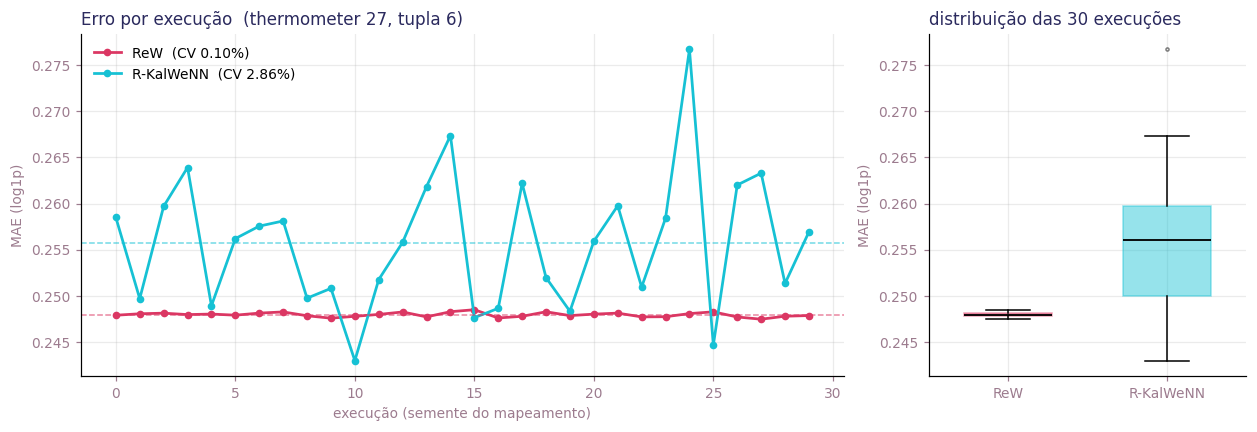

In [43]:
# ── figura: erro por execução e distribuição ────────────────────────────────
C_REW, C_KAL, C_EIXO, C_TIT = "#db3763", "#16c1d4", "#9c7b8e", "#2b2a5e"

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0), facecolor="white",
                       gridspec_kw={"width_ratios": [2.4, 1]})

s = np.arange(len(est_rew))
ax[0].plot(s, est_rew, "-o", ms=4, lw=1.8, color=C_REW,
           label=f"ReW  (CV {cv(est_rew):.2f}%)")
ax[0].plot(s, est_kal, "-o", ms=4, lw=1.8, color=C_KAL,
           label=f"R-KalWeNN  (CV {cv(est_kal):.2f}%)")
ax[0].axhline(est_rew.mean(), color=C_REW, ls="--", lw=1, alpha=.6)
ax[0].axhline(est_kal.mean(), color=C_KAL, ls="--", lw=1, alpha=.6)
ax[0].set(xlabel="execução (semente do mapeamento)", ylabel="MAE (log1p)")
ax[0].set_title(f"Erro por execução  (thermometer {THERM_1}, tupla {ADDR_1})",
                color=C_TIT, fontsize=11, loc="left")
ax[0].legend(frameon=False, fontsize=9)

bp = ax[1].boxplot([est_rew, est_kal], widths=.55, patch_artist=True,
                   medianprops=dict(color="black", lw=1.2),
                   flierprops=dict(marker=".", ms=4, alpha=.5))
for caixa, cor in zip(bp["boxes"], [C_REW, C_KAL]):
    caixa.set(facecolor=cor, alpha=.45, edgecolor=cor)
ax[1].set_xticklabels(["ReW", "R-KalWeNN"])
ax[1].set_ylabel("MAE (log1p)")
ax[1].set_title("distribuição das 30 execuções", color=C_TIT, fontsize=11, loc="left")

for e in ax:
    e.tick_params(colors=C_EIXO, labelsize=9)
    e.xaxis.label.set_color(C_EIXO); e.yaxis.label.set_color(C_EIXO)
    for sp in ("top", "right"): e.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

---
## 3. Thermometer e tupla

Duas coisas medidas na mesma varredura. A primeira é como o erro se move quando
a resolução do termômetro e o tamanho da tupla mudam. A segunda é o que acontece
com a memória: quantos endereços passam a existir e quantas vezes cada um é
visitado.

As duas juntas definem o ponto de operação. O erro sozinho empurra a tupla para
cima, porque endereço maior separa mais os exemplos. A estrutura de acesso puxa
para baixo, porque com a tupla grande cada endereço passa a ser visto uma única
vez, o modelo vira consulta determinística e a memória cresce. O ponto escolhido
é o maior valor que ainda preserva revisita.

Os hiperparâmetros do filtro ficam no padrão da Seção 1, recalculado em cada
configuração, já que a mediana de visitas e as variâncias mudam com a
codificação.

In [ ]:
# ── varredura de thermometer x tupla ────────────────────────────────────────
SW3_THERM  = list(range(5, 31))
SW3_ADDR   = [2, 3, 4, 6, 9, 12, 18, 27, 36, 54]   # os mesmos do notebook 06
SW3_SEEDS  = (0, 1)     # 2 ordens por configuração, é varredura grande
SW3_MEDIA  = "K-HarmonicPower(2)"     # média de referência para a superfície
LIMIAR_VIS = 2.0                      # mediana mínima de visitas por endereço

linhas2, t0 = [], time.perf_counter()
for t in SW3_THERM:
    dt = DynamicThermometer([t] * N_ATRIB, mins, maxs)
    Xb_tr, Xb_te = dt.transform(X_train), dt.transform(X_test)
    for a in SW3_ADDR:
        mp = sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING)
        ret = Retina(a, mp)
        atr, ate = ret.enderecos(Xb_tr), ret.enderecos(Xb_te)
        idx = IndiceRK(ret, atr)
        slots_te = idx.slots(ate)

        cont, soma, soma2 = [], [], []
        for r_ in range(ret.n_rams):
            _, inv = np.unique(atr[:, r_], return_inverse=True)
            cont.append(np.bincount(inv))
            soma.append(np.bincount(inv, weights=y_train))
            soma2.append(np.bincount(inv, weights=y_train ** 2))
        n = np.concatenate(cont); s = np.concatenate(soma); s2 = np.concatenate(soma2)
        mu = s / n; mult = n > 1
        if mult.sum() < 2:
            continue
        dentro = float((s2[mult] - n[mult] * mu[mult] ** 2).sum() / (n[mult] - 1).sum())
        entre = float(max(np.var(mu[mult], ddof=1)
                          - dentro * float(np.mean(1.0 / n[mult])), 1e-6))
        med = float(np.median(n))
        hp = dict(p0_c=1.0, r_c=med, q_c=1.0 / med,
                  p0_y=1.0, r_y=dentro / entre, x0_c=0.0, x0_y=float(y_train.mean()))
        hp["q_y"] = hp["r_y"] / med ** 2

        maes = []
        for sd in SW3_SEEDS:
            mod = f(a, mp, indice=idx, seed=sd, **hp).fit(y=y_train)
            maes.append(avalia(mod, slots_te, y_test, [SW3_MEDIA])[SW3_MEDIA][0])

        rew = RegressionWiSARD(a, medias_rew()["HarmonicPower(2)"], mp).fit(Xb_tr, y_train)
        pr = np.asarray(rew.predict(Xb_te), dtype=float)
        if not np.isfinite(pr).all():
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)

        linhas2.append(dict(therm=t, address=a, n_rams=ret.n_rams,
                            enderecos=idx.n_celulas,
                            visitas_mediana=med, pct_uma=100.0 * float((n == 1).mean()),
                            frac_util=1.0 - len(n) / (N_TREINO * ret.n_rams),
                            MAE_kal=float(np.mean(maes)), MAE_kal_dp=float(np.std(maes)),
                            MAE_rew=mean_absolute_error(y_test, pr),
                            r_c=hp["r_c"], r_y=hp["r_y"]))
    print(f"  thermometer {t:>2} ... {time.perf_counter()-t0:5.1f}s")

sup = pd.DataFrame(linhas2)
sup.to_csv("varredura_therm_addr.csv", index=False)
print(f"\n{len(sup)} configurações, {time.perf_counter()-t0:.1f}s")
print(sup.nsmallest(8, "MAE_kal").to_string(index=False, float_format=lambda v: f"{v:.4f}"))

  thermometer  5 ...  12.6s
  thermometer  6 ...  24.2s
  thermometer  7 ...  36.8s
  thermometer  8 ...  50.3s
  thermometer  9 ...  65.7s
  thermometer 10 ...  82.5s
  thermometer 11 ... 103.5s
  thermometer 12 ... 124.9s
  thermometer 13 ... 152.6s
  thermometer 14 ... 183.2s
  thermometer 15 ... 215.6s
  thermometer 16 ... 259.1s
  thermometer 17 ... 292.1s
  thermometer 18 ... 326.4s
  thermometer 19 ... 364.3s
  thermometer 20 ... 403.8s
  thermometer 21 ... 456.8s
  thermometer 22 ... 501.7s
  thermometer 23 ... 546.4s
  thermometer 24 ... 597.8s
  thermometer 25 ... 646.4s
  thermometer 26 ... 696.8s
  thermometer 27 ... 749.9s
  thermometer 28 ... 806.1s
  thermometer 29 ... 864.7s
  thermometer 30 ... 929.1s

260 configurações, 929.1s
 therm  address  n_rams  enderecos  visitas_mediana  pct_uma  frac_util  MAE_kal  MAE_kal_dp  MAE_rew    r_c    r_y
    21       54     129      89647           1.0000  84.6955     0.2858   0.1476      0.0003   0.1346 1.0000 0.4240
    27       

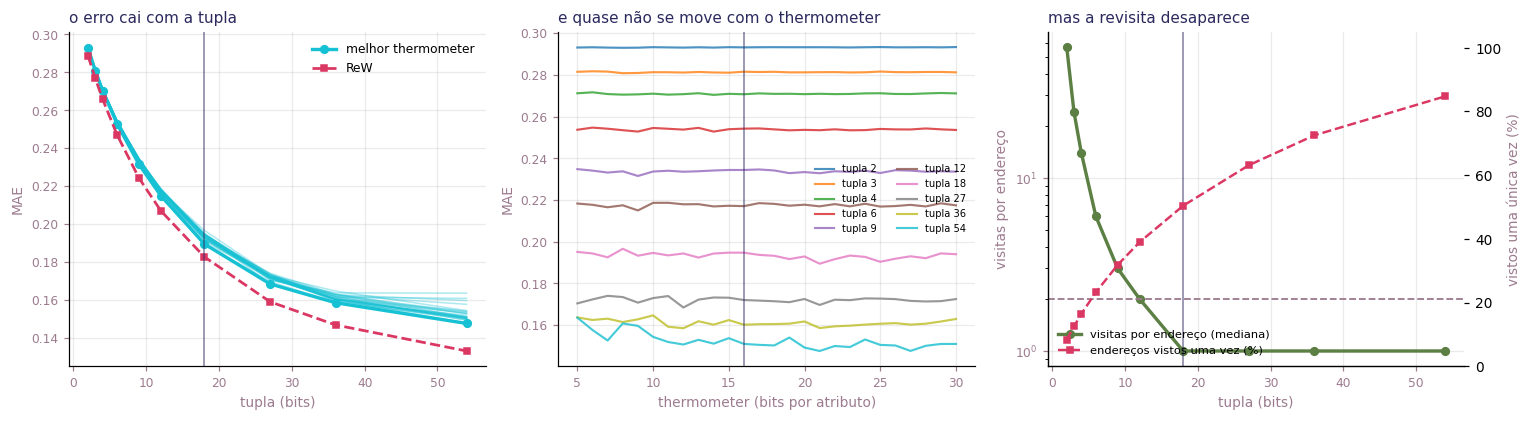

         MAE_kal  MAE_rew  visitas  uma_pct     rams
address                                             
2          0.293    0.289   57.000    8.292 2905.000
3          0.281    0.277   24.000   12.476 1936.500
4          0.270    0.266   14.000   16.412 1452.500
6          0.253    0.247    6.000   23.203  968.000
9          0.231    0.224    3.000   31.821  645.500
12         0.215    0.207    2.000   38.947  484.000
18         0.189    0.183    1.000   50.402  322.500
27         0.168    0.159    1.000   63.100  215.000
36         0.158    0.147    1.000   72.506  161.000
54         0.148    0.133    1.000   84.768  107.000

média de referência: Harmonic power
limiar de revisita: mediana de visitas >= 2
escolha: thermometer 16, tupla 18, MAE 0.1947, 295 RAM nodes, mediana de 2 visitas por endereço


In [45]:
# ── figuras: erro, visitas e o ponto escolhido ──────────────────────────────
if "sup" not in globals():
    sup = pd.read_csv("varredura_therm_addr.csv")

C_KAL, C_REW, C_VIS, C_EIXO, C_TIT = "#16c1d4", "#db3763", "#5c7f44", "#9c7b8e", "#2b2a5e"

# ponto escolhido: menor MAE entre as configurações que preservam revisita
elegiveis = sup[sup.visitas_mediana >= LIMIAR_VIS]
ESCOLHA = elegiveis.loc[elegiveis.MAE_kal.idxmin()]
T_OK, A_OK = int(ESCOLHA.therm), int(ESCOLHA.address)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), facecolor="white")

# (a) MAE contra tupla, uma linha por thermometer
for t, g in sup.groupby("therm"):
    g = g.sort_values("address")
    ax[0].plot(g.address, g.MAE_kal, "-", lw=1, alpha=.35, color=C_KAL)
melhor_a = sup.groupby("address").MAE_kal.min()
ax[0].plot(melhor_a.index, melhor_a.values, "o-", lw=2.2, ms=5, color=C_KAL,
           label="melhor thermometer")
ax[0].plot(sup.groupby("address").MAE_rew.min(), "s--", lw=1.8, ms=4, color=C_REW,
           label="ReW")
ax[0].set(xlabel="tupla (bits)", ylabel="MAE")
ax[0].set_title("o erro cai com a tupla", color=C_TIT, fontsize=10, loc="left")
ax[0].legend(frameon=False, fontsize=8)

# (b) MAE contra thermometer, uma linha por tupla
for a, g in sup.groupby("address"):
    g = g.sort_values("therm")
    ax[1].plot(g.therm, g.MAE_kal, "-", lw=1.4, alpha=.8, label=f"tupla {a}")
ax[1].set(xlabel="thermometer (bits por atributo)", ylabel="MAE")
ax[1].set_title("e quase não se move com o thermometer", color=C_TIT,
                fontsize=10, loc="left")
ax[1].legend(frameon=False, fontsize=6.5, ncol=2)

# (c) visitas por endereço contra tupla
vis = sup.groupby("address").agg(mediana=("visitas_mediana", "median"),
                                 uma=("pct_uma", "median"))
ax[2].plot(vis.index, vis.mediana, "o-", lw=2.2, ms=5, color=C_VIS,
           label="visitas por endereço (mediana)")
ax[2].axhline(LIMIAR_VIS, color=C_EIXO, ls="--", lw=1.2)
ax[2].set(xlabel="tupla (bits)", ylabel="visitas por endereço", yscale="log")
a2 = ax[2].twinx()
a2.plot(vis.index, vis.uma, "s--", lw=1.6, ms=4, color=C_REW,
        label="endereços vistos uma vez (%)")
a2.set_ylabel("vistos uma única vez (%)", color=C_EIXO); a2.set_ylim(0, 105); a2.grid(False)
ax[2].set_title("mas a revisita desaparece", color=C_TIT, fontsize=10, loc="left")
h1, l1 = ax[2].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
ax[2].legend(h1 + h2, l1 + l2, frameon=False, fontsize=7.5, loc="lower left")

for e in ax:
    e.axvline(A_OK, color=C_TIT, lw=1.2, alpha=.5) if e is not ax[1] else None
    e.tick_params(colors=C_EIXO, labelsize=8)
    e.xaxis.label.set_color(C_EIXO); e.yaxis.label.set_color(C_EIXO)
ax[1].axvline(T_OK, color=C_TIT, lw=1.2, alpha=.5)
plt.tight_layout(); plt.show()

print(sup.groupby("address").agg(
    MAE_kal=("MAE_kal", "min"), MAE_rew=("MAE_rew", "min"),
    visitas=("visitas_mediana", "median"), uma_pct=("pct_uma", "median"),
    rams=("n_rams", "median")).to_string(float_format=lambda v: f"{v:.3f}"))
print(f"\nmédia de referência: {rotulo(SW3_MEDIA)}")
print(f"limiar de revisita: mediana de visitas >= {LIMIAR_VIS:g}")
print(f"escolha: thermometer {T_OK}, tupla {A_OK}, "
      f"MAE {ESCOLHA.MAE_kal:.4f}, {int(ESCOLHA.n_rams)} RAM nodes, "
      f"mediana de {ESCOLHA.visitas_mediana:.0f} visitas por endereço")

---
## 4. Hiperparâmetros do filtro

Com o ponto de operação fixado na Seção 3, varremos um hiperparâmetro por vez em
torno do valor padrão, mantendo os outros cinco parados. São seis painéis, um
para cada: `p0_c`, `q_c` e `r_c` no campo do peso, e `p0_y`, `q_y` e `r_y` no
campo da estimativa. O eixo horizontal está em escala logarítmica e a linha
vertical marca o valor padrão.

Duas leituras esperadas. O `q` nunca chega a zero, porque com ruído de processo
nulo a recursão perde a dependência da ordem de apresentação e deixa de ser um
filtro. E os painéis de `p0` e `r` de um mesmo campo devem sair espelhados, com
o erro subindo de um lado onde desce do outro, já que aumentar a incerteza
inicial e diminuir o ruído de observação levam a célula ao mesmo
comportamento.

padrão neste ponto de operação: {'p0_c': 1.0, 'r_c': 2.0, 'q_c': 0.5, 'p0_y': 1.0, 'r_y': 0.900238, 'x0_c': 0.0, 'q_y': 0.225059}
  p0_c  padrão            1   grade [0.1, 10]   dentro
  q_c   padrão          0.5   grade [0.003, 1]   dentro
  r_c   padrão            2   grade [0.5, 30]   dentro
  p0_y  padrão            1   grade [0.1, 10]   dentro
  q_y   padrão     0.225059   grade [0.0005, 0.5]   dentro
  r_y   padrão     0.900238   grade [0.01, 5]   dentro

28 pontos em 8.5s


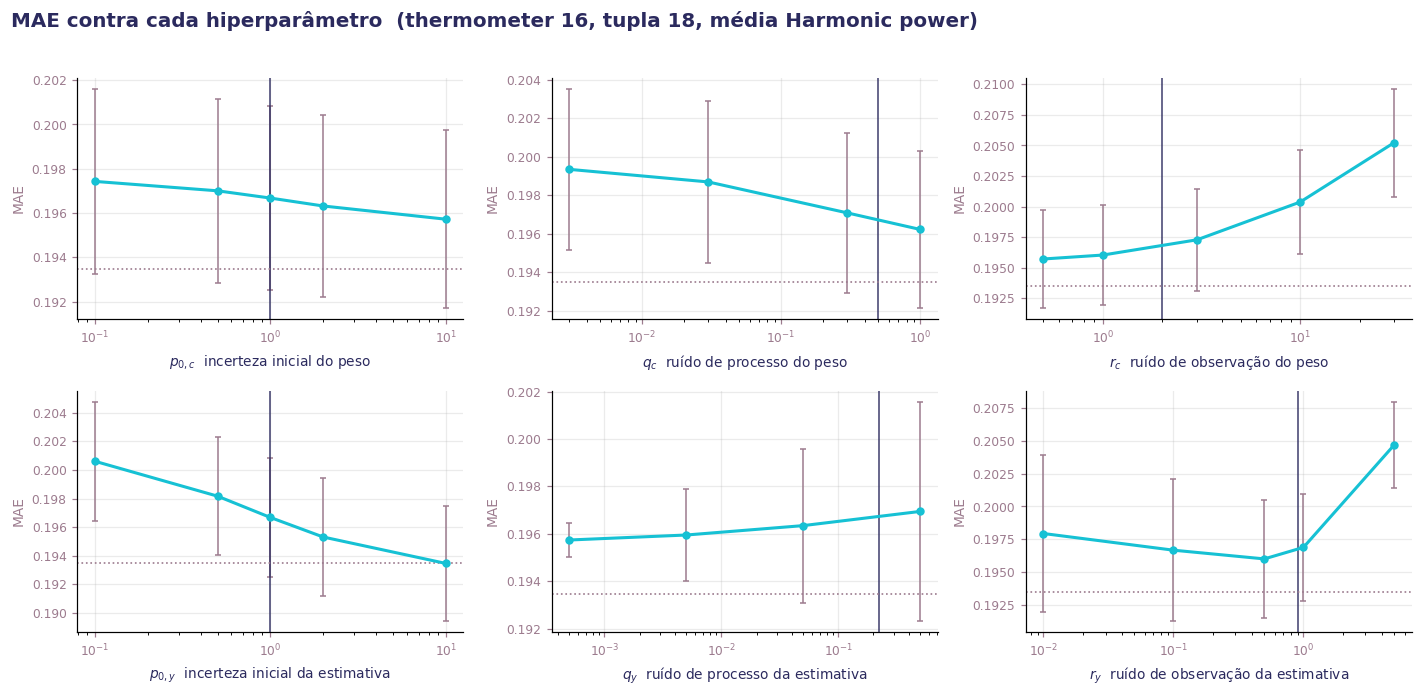


melhor nível de cada hiperparâmetro

  p0_c  padrão            1   melhor           10   MAE 0.1957   MAIOR nível
  q_c   padrão          0.5   melhor            1   MAE 0.1962   MAIOR nível
  r_c   padrão            2   melhor          0.5   MAE 0.1957   MENOR nível
  p0_y  padrão            1   melhor           10   MAE 0.1935   MAIOR nível
  q_y   padrão     0.225059   melhor       0.0005   MAE 0.1957   MENOR nível
  r_y   padrão     0.900238   melhor          0.5   MAE 0.1960   interior


In [46]:
# ── um parâmetro por vez, em torno do padrão ────────────────────────────────
SEEDS_4 = (0, 1, 2)     # 3 ordens de apresentação por ponto da grade
MEDIA_4 = SW3_MEDIA

# Grade explícita de cada hiperparâmetro, no formato do notebook 06. Varre-se um
# por vez: os outros cinco ficam parados no valor padrão medido no treino.
# Nenhum q é zero: sem ruído de processo a recursão perde a dependência da ordem
# de apresentação e deixa de ser um filtro. O menor nível de cada q é pequeno,
# não nulo.
#
#   p0_c  incerteza inicial do peso
#   r_c   em visitas: a confiança chega à metade na visita r_c
#   q_c   ruído de processo do peso, do quase estático ao muito esquecido
#   p0_y  incerteza inicial da estimativa
#   r_y   quanto uma visita isolada vale contra o que o endereço já sabia
#   q_y   ruído de processo da estimativa

SW_P0_C = [0.1, 0.5, 1.0, 2.0, 10.0]
SW_R_C  = [0.5, 1.0, 3.0, 10.0, 30.0]
SW_Q_C  = [3e-3, 3e-2, 3e-1, 1.0]

SW_P0_Y = [0.1, 0.5, 1.0, 2.0, 10.0]
SW_R_Y  = [0.01, 0.1, 0.5, 1.0, 5.0]
SW_Q_Y  = [5e-4, 5e-3, 5e-2, 5e-1]

GRADES_4 = {"p0_c": SW_P0_C, "q_c": SW_Q_C, "r_c": SW_R_C,
            "p0_y": SW_P0_Y, "q_y": SW_Q_Y, "r_y": SW_R_Y}
PARAMS_4 = list(GRADES_4)
ROT_4 = {"p0_c": "$p_{0,c}$  incerteza inicial do peso",
         "q_c": "$q_c$  ruído de processo do peso",
         "r_c": "$r_c$  ruído de observação do peso",
         "p0_y": "$p_{0,y}$  incerteza inicial da estimativa",
         "q_y": "$q_y$  ruído de processo da estimativa",
         "r_y": "$r_y$  ruído de observação da estimativa"}

dt_4 = DynamicThermometer([T_OK] * N_ATRIB, mins, maxs)
Xb_tr4, Xb_te4 = dt_4.transform(X_train), dt_4.transform(X_test)
map_4 = sorteia_mapping(Xb_tr4.shape[1], A_OK, seed=SEED_MAPPING)
ret_4 = Retina(A_OK, map_4)
idx_4 = IndiceRK(ret_4, ret_4.enderecos(Xb_tr4))
slots_te4 = idx_4.slots(ret_4.enderecos(Xb_te4))

lin = sup[(sup.therm == T_OK) & (sup.address == A_OK)].iloc[0]
med_4 = float(lin.visitas_mediana)
PADRAO_4 = dict(p0_c=1.0, r_c=float(lin.r_c), q_c=1.0 / med_4,
                p0_y=1.0, r_y=float(lin.r_y), x0_c=0.0, x0_y=float(y_train.mean()))
PADRAO_4["q_y"] = PADRAO_4["r_y"] / med_4 ** 2
print("padrão neste ponto de operação:",
      {k: round(v, 6) for k, v in PADRAO_4.items() if k != "x0_y"})

for par, grade in GRADES_4.items():
    dentro = min(grade) <= PADRAO_4[par] <= max(grade)
    print(f"  {par:5s} padrão {PADRAO_4[par]:>12.6g}   grade [{min(grade):g}, {max(grade):g}]"
          f"   {'dentro' if dentro else '>>> FORA DA GRADE <<<'}")
print()

linhas4, t0 = [], time.perf_counter()
for par, grade in GRADES_4.items():
    for v in grade:
        hp = dict(PADRAO_4); hp[par] = v
        maes = []
        for sd in SEEDS_4:
            mod = RKalWeNN(A_OK, map_4, indice=idx_4, seed=sd, **hp).fit(y=y_train)
            maes.append(avalia(mod, slots_te4, y_test, [MEDIA_4])[MEDIA_4][0])
        linhas4.append(dict(parametro=par, valor=v,
                            MAE=float(np.mean(maes)), MAE_dp=float(np.std(maes))))
sens = pd.DataFrame(linhas4)
sens.to_csv("sensibilidade_kalman.csv", index=False)
print(f"{len(sens)} pontos em {time.perf_counter()-t0:.1f}s")

C_L, C_EIXO, C_TIT = "#16c1d4", "#9c7b8e", "#2b2a5e"
piso4 = float(sens.MAE.min())
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), facecolor="white")
for a_, par in zip(ax.ravel(), PARAMS_4):
    g = sens[sens.parametro == par].sort_values("valor")
    a_.errorbar(g.valor, g.MAE, yerr=g.MAE_dp, fmt="o-", lw=2, ms=4.5,
                color=C_L, ecolor=C_EIXO, elinewidth=1, capsize=2)
    a_.axvline(PADRAO_4[par], color=C_TIT, lw=1.3, alpha=.7)
    a_.axhline(piso4, color=C_EIXO, ls=":", lw=1.1)
    a_.set(xscale="log", xlabel=ROT_4[par], ylabel="MAE")
    a_.tick_params(colors=C_EIXO, labelsize=8)
    a_.xaxis.label.set_color(C_TIT); a_.yaxis.label.set_color(C_EIXO)
fig.suptitle(f"MAE contra cada hiperparâmetro  (thermometer {T_OK}, tupla {A_OK}, média {rotulo(MEDIA_4)})",
             fontsize=13, fontweight="bold", color=C_TIT, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print("\nmelhor nível de cada hiperparâmetro\n")
for par in PARAMS_4:
    g = sens[sens.parametro == par]
    b = g.loc[g.MAE.idxmin()]
    borda = ("MENOR nível" if b.valor == min(GRADES_4[par])
             else "MAIOR nível" if b.valor == max(GRADES_4[par]) else "interior")
    print(f"  {par:5s} padrão {PADRAO_4[par]:>12.6g}   melhor {b.valor:>12.6g}"
          f"   MAE {b.MAE:.4f}   {borda}")